# Flujo sobre un escalón descendente
**Mecánica de Fluidos · Proyecto final**

Un fluido viene por un canal, encuentra un escalón hacia abajo y el canal se ensancha al doble. El flujo **no puede
dar la vuelta a la esquina**: se despega, deja atrás un remolino (zona de recirculación) y se vuelve a pegar al piso más
adelante. Este notebook resuelve las **ecuaciones de Navier–Stokes** en la computadora para ver ese remolino y medir
qué tan largo es.

**Cómo usarlo:** *Kernel → Restart & Run All* (unos 3 min). Sólo necesita `numpy`, `scipy` y `matplotlib`.

| Bloque | Qué hay |
|---|---|
| 0 | Librerías y parámetros (cambiar `RE` aquí para la demo en vivo) |
| 1 | La física: ecuaciones, condiciones de frontera, supuestos |
| 2 | La idea del método numérico en 3 pasos |
| 3 | El código, función por función |
| 4 | Caso base y animación |
| 5 | Análisis paramétrico: viscosidad (Re), malla y paso de tiempo |
| 6 | Comparación con la literatura y conclusiones |

Se partió del notebook *Combined backward facing step* (kangluosee/CFD-Python) como referencia del problema;
el código de aquí se escribió desde cero con un método más simple.

## 0. Librerías y parámetros

In [1]:
import numpy as np                       # arreglos y operaciones vectorizadas
import scipy.sparse as sps               # matrices dispersas (casi todo ceros)
import scipy.sparse.linalg as spla       # resolver sistemas lineales dispersos
import matplotlib.pyplot as plt          # gráficas
import matplotlib.patches as patches     # para dibujar el escalón
from matplotlib.animation import FuncAnimation, PillowWriter   # animación
from IPython.display import HTML, display
from pathlib import Path

FIG = Path("figures")                    # carpeta donde se guardan las figuras
FIG.mkdir(exist_ok=True)

In [2]:
# ======================= PARÁMETROS (cambiar aquí en la demo en vivo) =======================
RE = 200        # número de Reynolds  Re = U*H/nu  (bajar nu = subir Re)
NY = 20         # número de celdas en la altura del canal
L  = 15.0       # largo del canal después del escalón (en alturas H)
# ===========================================================================================

H = 1.0         # altura del canal después del escalón
S = 0.5         # altura del escalón
U = 1.0         # velocidad media a la entrada
GAMMA = 0.5     # mezcla para la convección: 0 = promedio puro, 1 = tomar el valor de donde viene el flujo

## 1. La física

### Geometría
Canal de altura $H = 1$ después del escalón; el escalón mide $S = H/2$, así que el canal de entrada mide $h = H/2$
y el canal **se ensancha al doble**. La entrada está justo en el plano del escalón ($x = 0$).

### Ecuaciones (las de clase, en forma adimensional)
$$\frac{\partial u}{\partial x} + \frac{\partial v}{\partial y} = 0 \qquad \text{(continuidad: no se crea ni se pierde masa)}$$
$$\frac{\partial u}{\partial t} + \underbrace{\frac{\partial (uu)}{\partial x} + \frac{\partial (vu)}{\partial y}}_{\text{convección}} = -\frac{\partial p}{\partial x} + \underbrace{\frac{1}{Re}\left(\frac{\partial^2 u}{\partial x^2} + \frac{\partial^2 u}{\partial y^2}\right)}_{\text{difusión viscosa}}$$
$$\frac{\partial v}{\partial t} + \frac{\partial (uv)}{\partial x} + \frac{\partial (vv)}{\partial y} = -\frac{\partial p}{\partial y} + \frac{1}{Re}\left(\frac{\partial^2 v}{\partial x^2} + \frac{\partial^2 v}{\partial y^2}\right)$$

Se midió todo en unidades de $H$ (longitud), $U$ (velocidad media de entrada) y $\rho U^2$ (presión). Así sólo queda un
parámetro, el **número de Reynolds** $Re = UH/\nu$: inercia contra viscosidad. **Bajar la viscosidad es lo mismo que subir $Re$.**

> La convección se escribe como $\partial(uu)/\partial x + \partial(vu)/\partial y$ en vez de $u\,\partial u/\partial x + v\,\partial u/\partial y$:
> es lo mismo gracias a la continuidad, y esta forma ("lo que entra menos lo que sale") es la que conserva mejor el momento.

### Supuestos
2D, incompresible ($\rho$ constante), newtoniano ($\nu$ constante), sin cambios de temperatura, laminar ($Re \le 600$),
sin gravedad (sólo añade presión hidrostática y no cambia el movimiento).

### Condiciones de frontera e inicial
| Dónde | Velocidad | Presión |
|---|---|---|
| Entrada ($x=0$, arriba del escalón) | parábola de Poiseuille, $u = 6U\eta(1-\eta)$, $v = 0$ | $\partial p/\partial n = 0$ |
| Cara del escalón ($x=0$, $y<S$) | $u = v = 0$ (no deslizamiento) | $\partial p/\partial n = 0$ |
| Piso y techo | $u = v = 0$ (no deslizamiento) | $\partial p/\partial n = 0$ |
| Salida ($x = L$) | $\partial u/\partial x = \partial v/\partial x = 0$ (flujo ya desarrollado) | $p = 0$ (referencia) |

**Condición inicial:** fluido quieto, $u = v = 0$. Se avanza en el tiempo hasta que el flujo deja de cambiar (estado estacionario).

### ¿Qué esperamos ver?
Al llegar a la esquina, el fluido pegado a la pared no tiene suficiente inercia para seguir el cambio de geometría contra el
aumento de presión del ensanchamiento: **se separa**. Debajo queda un remolino con $u < 0$. Más adelante el chorro se abre,
toca el piso en el **punto de reacoplamiento** $x_r$ (ahí el esfuerzo cortante en la pared es cero) y el perfil vuelve a ser
una parábola. A mayor $Re$ el remolino es más largo, y a partir de $Re \approx 400$ aparece un segundo remolino en el techo.

## 2. La idea del método numérico

**Discretizar:** partimos el canal en celdas cuadradas de lado $\Delta x$ y cambiamos cada derivada por una diferencia, por ejemplo
$$\frac{\partial^2 u}{\partial x^2} \approx \frac{u_E - 2u_P + u_W}{\Delta x^2}, \qquad \frac{\partial p}{\partial x} \approx \frac{p_{derecha} - p_{izquierda}}{\Delta x}$$
($P$ = el punto, $E, W, N, S$ = vecinos este, oeste, norte, sur).

**Malla escalonada:** la presión se guarda en el centro de cada celda y las velocidades en las caras. Así la velocidad de
cada cara queda justo entre dos presiones y la diferencia de presión es la fuerza que la empuja.

![malla](figures/malla_escalonada.png)

**El problema de la presión:** no hay una ecuación "para $p$"; la presión es lo que se necesita para que se cumpla la
continuidad. Por eso cada paso de tiempo $\Delta t$ se hace en **3 pasos** (método de proyección de Chorin, 1968):

1. **Velocidad de prueba** con convección y difusión, ignorando la presión:
   $u^* = u^n + \Delta t\,[\text{difusión} - \text{convección}]$
2. **Presión:** $u^*$ no cumple continuidad. Buscamos la $p$ que la corrige; sale de tomar la divergencia del paso 3:
   $$\nabla^2 p = \frac{\nabla \cdot \mathbf{u}^*}{\Delta t}$$
   Es un sistema lineal $A\,p = b$ (una ecuación por celda), que se resuelve con la computadora.
3. **Corrección:** $\mathbf{u}^{n+1} = \mathbf{u}^* - \Delta t\,\nabla p$. Ahora $\nabla\cdot\mathbf{u}^{n+1} = 0$.

**Estabilidad (condición CFL):** en un paso de tiempo el fluido no debe avanzar más de una celda:
$\Delta t \le \Delta x / u_{max}$. Usamos la mitad de ese límite. Si no se respeta, los errores crecen y la solución "explota"
(lo probamos en el bloque 5.3).

**Convección:** el valor de $u$ en una cara se toma como el promedio de los dos vecinos, corrido un poco hacia el vecino
de donde viene el flujo (`GAMMA = 0.5`). El promedio puro es más preciso pero inestable con este $\Delta t$; tomar sólo el valor
de donde viene el flujo es muy estable pero "suaviza" de más. La mezcla es un compromiso.

## 3. El código
### 3.1 Malla y perfil de entrada

In [3]:
def crear_malla(NY, L):
    """Malla de celdas cuadradas de lado dx = dy sobre el rectángulo [0, L] x [0, H]."""
    dx = H / NY                              # lado de cada celda
    NX = round(L / dx)                       # número de celdas a lo largo
    x_p = (np.arange(NX) + 0.5) * dx         # x de los centros de celda (donde vive p)
    y_p = (np.arange(NY) + 0.5) * dx         # y de los centros de celda
    x_u = np.arange(NX + 1) * dx             # x de las caras verticales (donde vive u)
    return {"NX": NX, "NY": NY, "dx": dx, "L": L, "x_p": x_p, "y_p": y_p, "x_u": x_u}


def perfil_entrada(y):
    """Perfil parabólico (flujo de Poiseuille) en el canal de entrada S < y < H; cero frente al escalón."""
    eta = (y - S) / (H - S)                  # 0 en el borde del escalón, 1 en la pared de arriba
    return np.where(y > S, 6 * U * eta * (1 - eta), 0.0)   # el 6 hace que la velocidad media sea U

### 3.2 Matriz de la ecuación de presión (paso 2)

In [4]:
def matriz_presion(NX, NY, dx):
    """Arma y factoriza la matriz de la ecuación de Poisson  lap(p) = b.

    Para cada celda: sum_vecinos (p_vecino - p_celda) / dx^2 = b_celda.
    - Entrada, escalón y paredes: dp/dn = 0  -> ese vecino simplemente no se suma.
    - Salida: p = 0 en la cara, que está a dx/2 del centro -> aporta -2 p_celda / dx^2.
    """
    N = NX * NY                              # una ecuación por celda
    A = sps.lil_matrix((N, N))               # matriz vacía (formato fácil de llenar)
    for i in range(NX):                      # recorre columnas de celdas (dirección x)
        for j in range(NY):                  # recorre filas de celdas (dirección y)
            k = i * NY + j                   # número de la celda (i, j) en la lista
            if i < NX - 1:                   # vecino de la derecha
                A[k, k + NY] = 1; A[k, k] -= 1
            else:                            # última celda: la cara derecha es la salida (p = 0)
                A[k, k] -= 2
            if i > 0:                        # vecino de la izquierda (en i = 0 está la entrada)
                A[k, k - NY] = 1; A[k, k] -= 1
            if j < NY - 1:                   # vecino de arriba (en j = NY-1 está la pared)
                A[k, k + 1] = 1; A[k, k] -= 1
            if j > 0:                        # vecino de abajo (en j = 0 está el piso)
                A[k, k - 1] = 1; A[k, k] -= 1
    A = A.tocsc() / dx**2                    # formato rápido para resolver
    return spla.splu(A)                      # factorización LU: se hace UNA vez y se reutiliza

### 3.3 Condiciones de frontera

In [5]:
def fronteras(u, v, u_entrada):
    """Aplica las condiciones de frontera.
    u tiene forma (NX+1, NY+2) y v (NX+2, NY+1): incluyen una 'celda fantasma' fuera del dominio."""
    u[0, 1:-1] = u_entrada        # entrada: perfil parabólico (0 en la cara del escalón)
    v[0, :] = -v[1, :]            # entrada: v = 0  (fantasma = espejo, el promedio en x = 0 da cero)
    u[:, 0] = -u[:, 1]            # piso: u = 0  (no deslizamiento, con fantasma espejo)
    u[:, -1] = -u[:, -2]          # techo: u = 0
    v[:, 0] = 0.0                 # piso: v = 0  (v está justo sobre la pared)
    v[:, -1] = 0.0                # techo: v = 0
    v[-1, :] = v[-2, :]           # salida: dv/dx = 0

### 3.4 Convección y difusión (paso 1)

In [6]:
def valor_en_cara(f_izq, f_der, vel):
    """Valor de f en la cara entre dos nodos: el promedio, corrido un poco (GAMMA)
    hacia el lado de donde viene el flujo (vel > 0: de la izquierda)."""
    return 0.5 * (f_izq + f_der) - 0.5 * GAMMA * np.sign(vel) * (f_der - f_izq)


def aceleracion_u(u, v, nu, dx):
    """Lado derecho de la ecuación de x sin la presión:  nu*lap(u) - d(uu)/dx - d(vu)/dy."""
    P = u[1:-1, 1:-1]                          # u en el nodo
    E, W = u[2:, 1:-1], u[:-2, 1:-1]           # vecinos este y oeste
    N, Sur = u[1:-1, 2:], u[1:-1, :-2]         # vecinos norte y sur
    difusion = nu * (E + W + N + Sur - 4 * P) / dx**2       # laplaciano de 5 puntos

    u_e, u_w = 0.5 * (P + E), 0.5 * (W + P)                 # velocidad que cruza las caras este/oeste
    v_n = 0.5 * (v[1:-2, 1:] + v[2:-1, 1:])                 # velocidad que cruza la cara norte
    v_s = 0.5 * (v[1:-2, :-1] + v[2:-1, :-1])               # velocidad que cruza la cara sur
    conveccion = (u_e * valor_en_cara(P, E, u_e) - u_w * valor_en_cara(W, P, u_w)) / dx \
               + (v_n * valor_en_cara(P, N, v_n) - v_s * valor_en_cara(Sur, P, v_s)) / dx
    return difusion - conveccion


def aceleracion_v(u, v, nu, dx):
    """Lado derecho de la ecuación de y sin la presión:  nu*lap(v) - d(uv)/dx - d(vv)/dy."""
    P = v[1:-1, 1:-1]
    E, W = v[2:, 1:-1], v[:-2, 1:-1]
    N, Sur = v[1:-1, 2:], v[1:-1, :-2]
    difusion = nu * (E + W + N + Sur - 4 * P) / dx**2

    u_e = 0.5 * (u[1:, 1:-2] + u[1:, 2:-1])                 # velocidad que cruza la cara este
    u_w = 0.5 * (u[:-1, 1:-2] + u[:-1, 2:-1])               # velocidad que cruza la cara oeste
    v_n, v_s = 0.5 * (P + N), 0.5 * (Sur + P)               # velocidad que cruza las caras norte/sur
    conveccion = (u_e * valor_en_cara(P, E, u_e) - u_w * valor_en_cara(W, P, u_w)) / dx \
               + (v_n * valor_en_cara(P, N, v_n) - v_s * valor_en_cara(Sur, P, v_s)) / dx
    return difusion - conveccion

### 3.5 El ciclo en el tiempo: los 3 pasos

In [7]:
def simular(Re, NY=20, L=15.0, dt=None, t_max=400.0, tol=1e-5, fotos_cada=0):
    """Resuelve Navier-Stokes desde el reposo hasta que el flujo deja de cambiar."""
    nu = 1.0 / Re                            # viscosidad adimensional
    m = crear_malla(NY, L)
    NX, dx = m["NX"], m["dx"]
    if dt is None:
        dt = 0.5 * dx / 1.5                  # mitad del límite CFL (velocidad máxima = 1.5 U)

    resolver_p = matriz_presion(NX, NY, dx)  # matriz de presión, factorizada una sola vez
    u_entrada = perfil_entrada(m["y_p"])
    u = np.zeros((NX + 1, NY + 2))           # condición inicial: fluido en reposo
    v = np.zeros((NX + 2, NY + 1))
    fronteras(u, v, u_entrada)

    t, n, estado = 0.0, 0, "tiempo máximo"
    hist_t, hist_cambio, fotos = [], [], []
    while t < t_max:
        u_viejo = u.copy()

        # PASO 1: velocidad de prueba, con convección y difusión pero SIN presión
        u_est, v_est = u.copy(), v.copy()
        u_est[1:-1, 1:-1] += dt * aceleracion_u(u, v, nu, dx)
        v_est[1:-1, 1:-1] += dt * aceleracion_v(u, v, nu, dx)
        u_est[-1, 1:-1] = u_est[-2, 1:-1]    # salida: du/dx = 0

        # PASO 2: presión que hace falta para que no se cree ni se pierda masa:  lap(p) = div(u_est)/dt
        div = (u_est[1:, 1:-1] - u_est[:-1, 1:-1] + v_est[1:-1, 1:] - v_est[1:-1, :-1]) / dx
        p = resolver_p.solve((div / dt).ravel()).reshape(NX, NY)

        # PASO 3: corregir la velocidad con el gradiente de presión:  u = u_est - dt * grad(p)
        u, v = u_est, v_est
        u[1:-1, 1:-1] -= dt * (p[1:, :] - p[:-1, :]) / dx
        u[-1, 1:-1] -= dt * (0.0 - p[-1, :]) / (dx / 2)       # salida: p = 0 en la cara
        v[1:-1, 1:-1] -= dt * (p[:, 1:] - p[:, :-1]) / dx
        fronteras(u, v, u_entrada)

        t += dt; n += 1
        cambio = np.max(np.abs(u - u_viejo)) / dt              # qué tan rápido cambia todavía el flujo
        if n % 10 == 0:
            hist_t.append(t); hist_cambio.append(cambio)
        if fotos_cada and n % fotos_cada == 0:
            fotos.append((t, u.copy(), v.copy()))
        if not np.isfinite(cambio) or cambio > 1e3:            # la solución explotó
            estado = "diverge"; break
        if cambio < tol and t > 5:                             # ya no cambia: estado estacionario
            estado = "converge"; break

    r = dict(m=m, Re=Re, nu=nu, dt=dt, u=u, v=v, p=p, t=t, pasos=n, estado=estado,
             hist_t=hist_t, hist_cambio=hist_cambio, fotos=fotos)
    if estado != "diverge":
        r["xr"] = reacoplamiento(r)
        r["burbuja_sup"] = burbuja_superior(r)
    txt = f"Re = {Re:4d} | NY = {NY:3d} | dt = {dt:.4f} | {estado:9s} en t = {t:6.1f} ({n} pasos)"
    if estado != "diverge":
        txt += f" | x_r/S = {r['xr']/S:.2f}"
    print(txt)
    return r

### 3.6 Resultados: punto de reacoplamiento, remolino superior y comprobación de masa

In [8]:
def reacoplamiento(r):
    """Punto donde el flujo se vuelve a pegar al piso: la u junto al piso pasa de negativa a positiva."""
    x = r["m"]["x_u"]
    u_piso = r["u"][:, 1]                     # u en la fila de celdas pegada al piso
    i_min = np.argmin(u_piso)                 # centro de la burbuja (flujo más negativo)
    for i in range(i_min, len(x) - 1):        # buscamos aguas abajo del centro de la burbuja
        if u_piso[i] < 0 <= u_piso[i + 1]:
            return x[i] - u_piso[i] * (x[i + 1] - x[i]) / (u_piso[i + 1] - u_piso[i])  # interpolación
    return np.nan


def burbuja_superior(r):
    """Inicio y fin de la zona con u < 0 junto al techo (None si no existe)."""
    x = r["m"]["x_u"]
    negativos = np.where(r["u"][:, -2] < 0)[0]   # nodos con flujo inverso junto al techo
    if len(negativos) == 0:
        return None
    return x[negativos[0]], x[negativos[-1]]


def velocidad_en_centros(r):
    """Promedia u y v a los centros de celda (para graficar)."""
    u, v = r["u"], r["v"]
    uc = 0.5 * (u[1:, 1:-1] + u[:-1, 1:-1])
    vc = 0.5 * (v[1:-1, 1:] + v[1:-1, :-1])
    return uc, vc


def divergencia_maxima(r):
    """Comprobación de conservación de masa: debe ser ~0."""
    u, v, dx = r["u"], r["v"], r["m"]["dx"]
    return np.max(np.abs((u[1:, 1:-1] - u[:-1, 1:-1] + v[1:-1, 1:] - v[1:-1, :-1]) / dx))

### 3.7 Gráficas

In [9]:
def dibujar_escalon(ax):
    ax.add_patch(patches.Rectangle((-0.6, 0), 0.6, S, fc="0.35", ec="k", hatch="///"))


def graficar_campos(r, x_max=8, archivo=None):
    """Velocidad con líneas de corriente, vorticidad y presión."""
    m = r["m"]; dx = m["dx"]
    uc, vc = velocidad_en_centros(r)
    vort = (vc[2:, 1:-1] - vc[:-2, 1:-1]) / (2 * dx) - (uc[1:-1, 2:] - uc[1:-1, :-2]) / (2 * dx)  # dv/dx - du/dy
    X, Y = np.meshgrid(m["x_p"], m["y_p"], indexing="ij")

    fig, ax = plt.subplots(3, 1, figsize=(12, 6.2), sharex=True, constrained_layout=True)
    c = ax[0].contourf(X, Y, np.hypot(uc, vc), levels=40, cmap="viridis")
    ax[0].streamplot(m["x_p"], m["y_p"], uc.T, vc.T, color="w", density=1.4, linewidth=0.5, arrowsize=0.6)
    fig.colorbar(c, ax=ax[0], label="|V| / U")
    ax[0].set_title(f"Re = {r['Re']}: velocidad y líneas de corriente  (x_r/S = {r['xr']/S:.2f})")
    w = np.percentile(np.abs(vort), 98)
    c = ax[1].contourf(X[1:-1, 1:-1], Y[1:-1, 1:-1], vort, levels=np.linspace(-w, w, 41), cmap="RdBu_r", extend="both")
    fig.colorbar(c, ax=ax[1], label="ω H / U"); ax[1].set_title("Vorticidad")
    c = ax[2].contourf(X, Y, r["p"], levels=40, cmap="coolwarm")
    fig.colorbar(c, ax=ax[2], label="p / ρU²"); ax[2].set_title("Presión")
    for a in ax:
        dibujar_escalon(a); a.axvline(r["xr"], color="r", ls="--", lw=1)
        a.set_xlim(-0.6, x_max); a.set_ylim(0, H); a.set_aspect("equal"); a.set_ylabel("y / H")
    ax[-1].set_xlabel("x / H")
    if archivo: fig.savefig(archivo, dpi=150)
    plt.show()


def graficar_perfiles(r, estaciones=(0, 1, 2, 3, 4, 6, 8), archivo=None):
    """Perfiles u(y) en varias posiciones x."""
    m = r["m"]
    fig, ax = plt.subplots(figsize=(12, 2.8), constrained_layout=True)
    for xs in estaciones:
        i = round(xs / m["dx"])
        ax.plot(xs + 0.8 * r["u"][i, 1:-1], m["y_p"], "b-")   # perfil dibujado a partir de x = xs
        ax.axvline(xs, color="0.6", lw=0.6)
    dibujar_escalon(ax)
    ax.axvline(r["xr"], color="r", ls="--", lw=1, label="reacoplamiento")
    ax.set_xlim(-0.6, max(estaciones) + 1.5); ax.set_ylim(0, H)
    ax.set_xlabel("x / H   (perfil dibujado como x + 0.8 u/U)"); ax.set_ylabel("y / H")
    ax.set_title(f"Perfiles de velocidad u(y), Re = {r['Re']}"); ax.legend(loc="upper right")
    if archivo: fig.savefig(archivo, dpi=150)
    plt.show()

## 4. Caso base

In [10]:
base = simular(RE, NY=NY, L=L, fotos_cada=15)
print(f"Divergencia máxima = {divergencia_maxima(base):.1e}   (≈ 0: la masa se conserva)")
print(f"Reacoplamiento: x_r = {base['xr']:.2f} H = {base['xr']/S:.2f} alturas de escalón")

Re =  200 | NY =  20 | dt = 0.0167 | converge  en t =   48.6 (2916 pasos) | x_r/S = 4.90
Divergencia máxima = 5.6e-15   (≈ 0: la masa se conserva)
Reacoplamiento: x_r = 2.45 H = 4.90 alturas de escalón


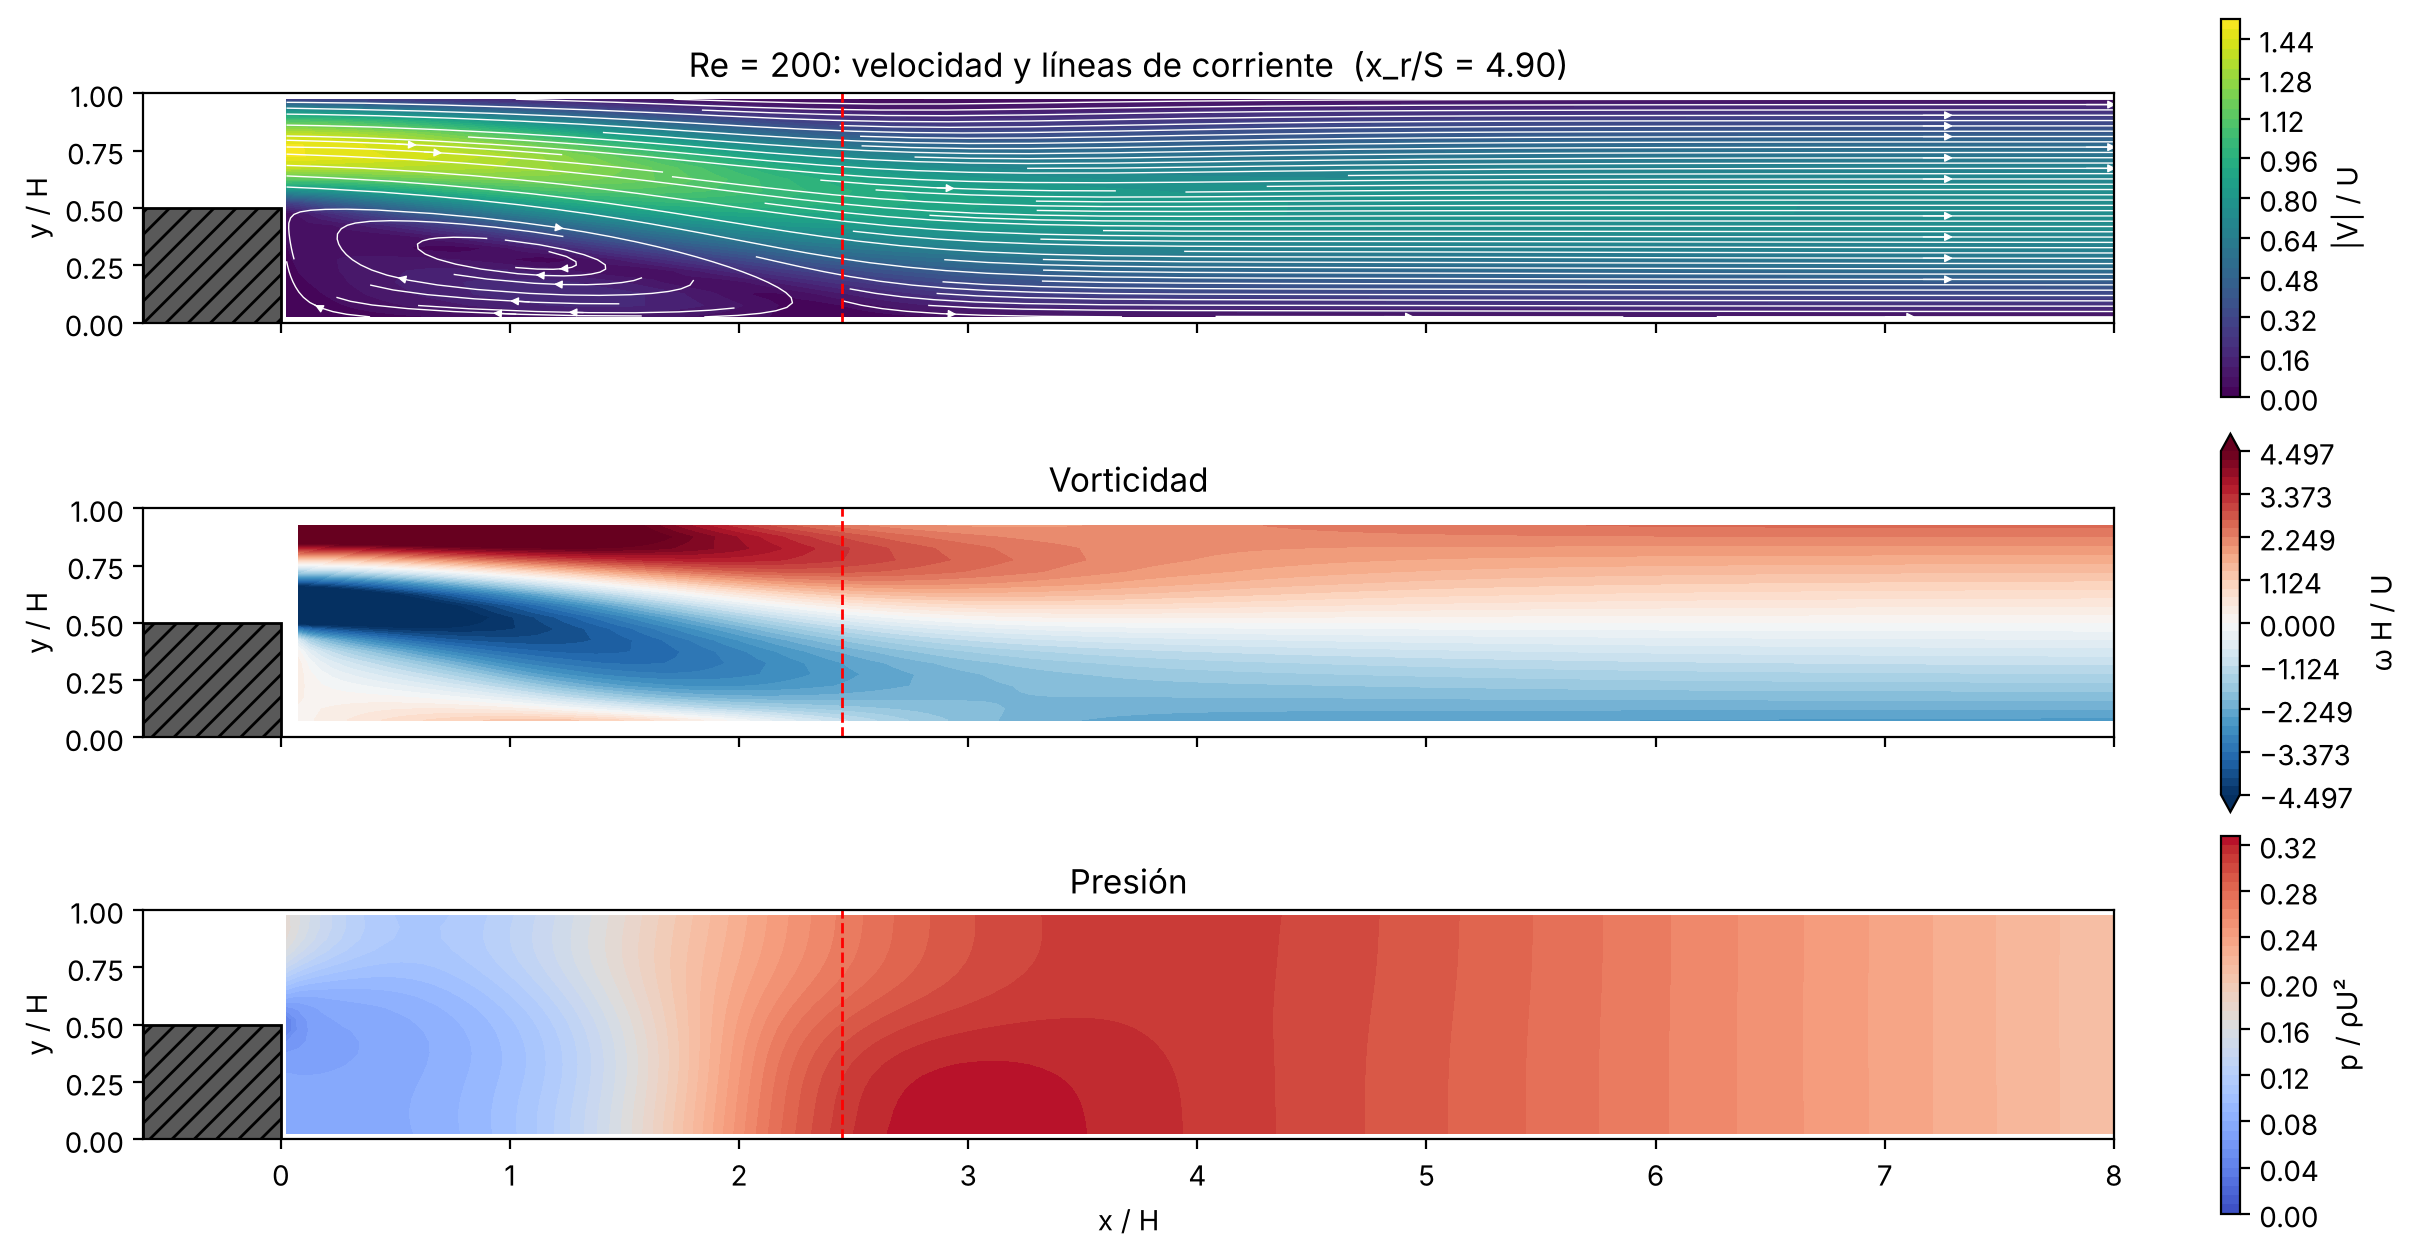

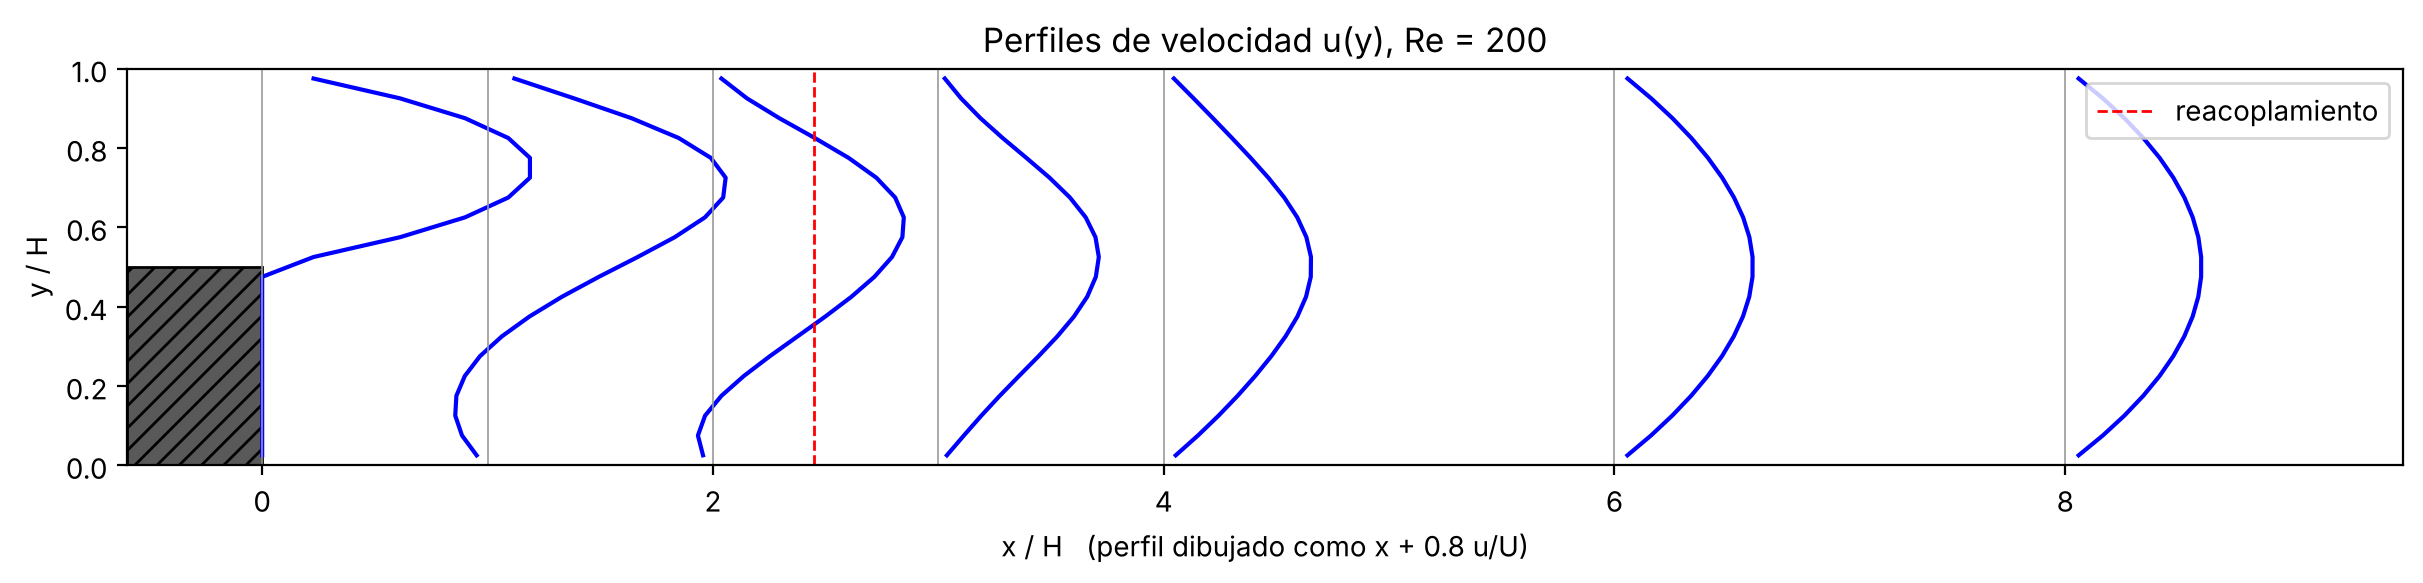

In [11]:
graficar_campos(base, archivo=FIG / "campos_base.png")
graficar_perfiles(base, archivo=FIG / "perfiles_base.png")

**¿Qué se ve?**
* **Velocidad:** el chorro sale del canal de entrada ($u_{max} = 1.5$) y abajo de él queda el remolino. Al final el perfil
  es otra parábola, más baja ($u_{max} = 0.75$) porque el mismo caudal pasa por un canal el doble de alto.
* **Vorticidad:** se concentra en la capa que separa el chorro del remolino (capa de corte), que nace en la esquina.
* **Presión:** sube después del escalón (el fluido se frena al ensancharse el canal, como en Bernoulli). Ese aumento de
  presión, un gradiente adverso, es lo que despega el flujo. Después baja poco a poco por la fricción con las paredes.

### Animación: el arranque desde el reposo

In [12]:
def animar(r, x_max=8, archivo=None):
    m = r["m"]
    fotos = r["fotos"][:: max(1, len(r["fotos"]) // 30)]       # como máximo ~30 cuadros
    fig, ax = plt.subplots(figsize=(10, 2.3), dpi=72, constrained_layout=True)

    def cuadro(k):
        t, u, v = fotos[k]
        uc = 0.5 * (u[1:, 1:-1] + u[:-1, 1:-1]); vc = 0.5 * (v[1:-1, 1:] + v[1:-1, :-1])
        ax.clear()
        ax.contourf(m["x_p"], m["y_p"], np.hypot(uc, vc).T, levels=np.linspace(0, 1.6, 33), cmap="viridis")
        ax.streamplot(m["x_p"], m["y_p"], uc.T, vc.T, color="w", density=1.2, linewidth=0.5, arrowsize=0.6)
        dibujar_escalon(ax)
        ax.set_xlim(-0.6, x_max); ax.set_ylim(0, H); ax.set_aspect("equal")
        ax.set_title(f"Re = {r['Re']}   t = {t:5.1f} H/U")

    ani = FuncAnimation(fig, cuadro, frames=len(fotos), interval=120)
    if archivo:
        ani.save(archivo, writer=PillowWriter(fps=8))
    plt.close(fig)
    return ani

display(HTML(animar(base, archivo=FIG / "transitorio.gif").to_jshtml()))

## 5. Análisis paramétrico
### 5.1 Viscosidad (número de Reynolds)
Se cambia $\nu = 1/Re$. Se usa un canal más largo ($L = 25H$) para que el remolino no llegue a la salida.

In [13]:
lista_re = [100, 200, 300, 400, 600]
casos_re = [simular(Re, NY=20, L=25.0, t_max=500) for Re in lista_re]

print("\n  Re     nu      x_r/S   remolino del techo (en H)")
for r in casos_re:
    b = r["burbuja_sup"]
    techo = f"{b[0]:.2f} a {b[1]:.2f}" if b else "no hay"
    print(f"{r['Re']:5d}  {r['nu']:.4f}  {r['xr']/S:6.2f}   {techo}")

Re =  100 | NY =  20 | dt = 0.0167 | converge  en t =   23.9 (1436 pasos) | x_r/S = 3.01


Re =  200 | NY =  20 | dt = 0.0167 | converge  en t =   48.6 (2916 pasos) | x_r/S = 4.90


Re =  300 | NY =  20 | dt = 0.0167 | converge  en t =   83.6 (5019 pasos) | x_r/S = 6.52


Re =  400 | NY =  20 | dt = 0.0167 | converge  en t =  139.6 (8376 pasos) | x_r/S = 7.90


Re =  600 | NY =  20 | dt = 0.0167 | converge  en t =  316.2 (18973 pasos) | x_r/S = 9.75

  Re     nu      x_r/S   remolino del techo (en H)
  100  0.0100    3.01   no hay
  200  0.0050    4.90   no hay
  300  0.0033    6.52   no hay
  400  0.0025    7.90   3.95 a 4.05
  600  0.0017    9.75   4.00 a 6.70


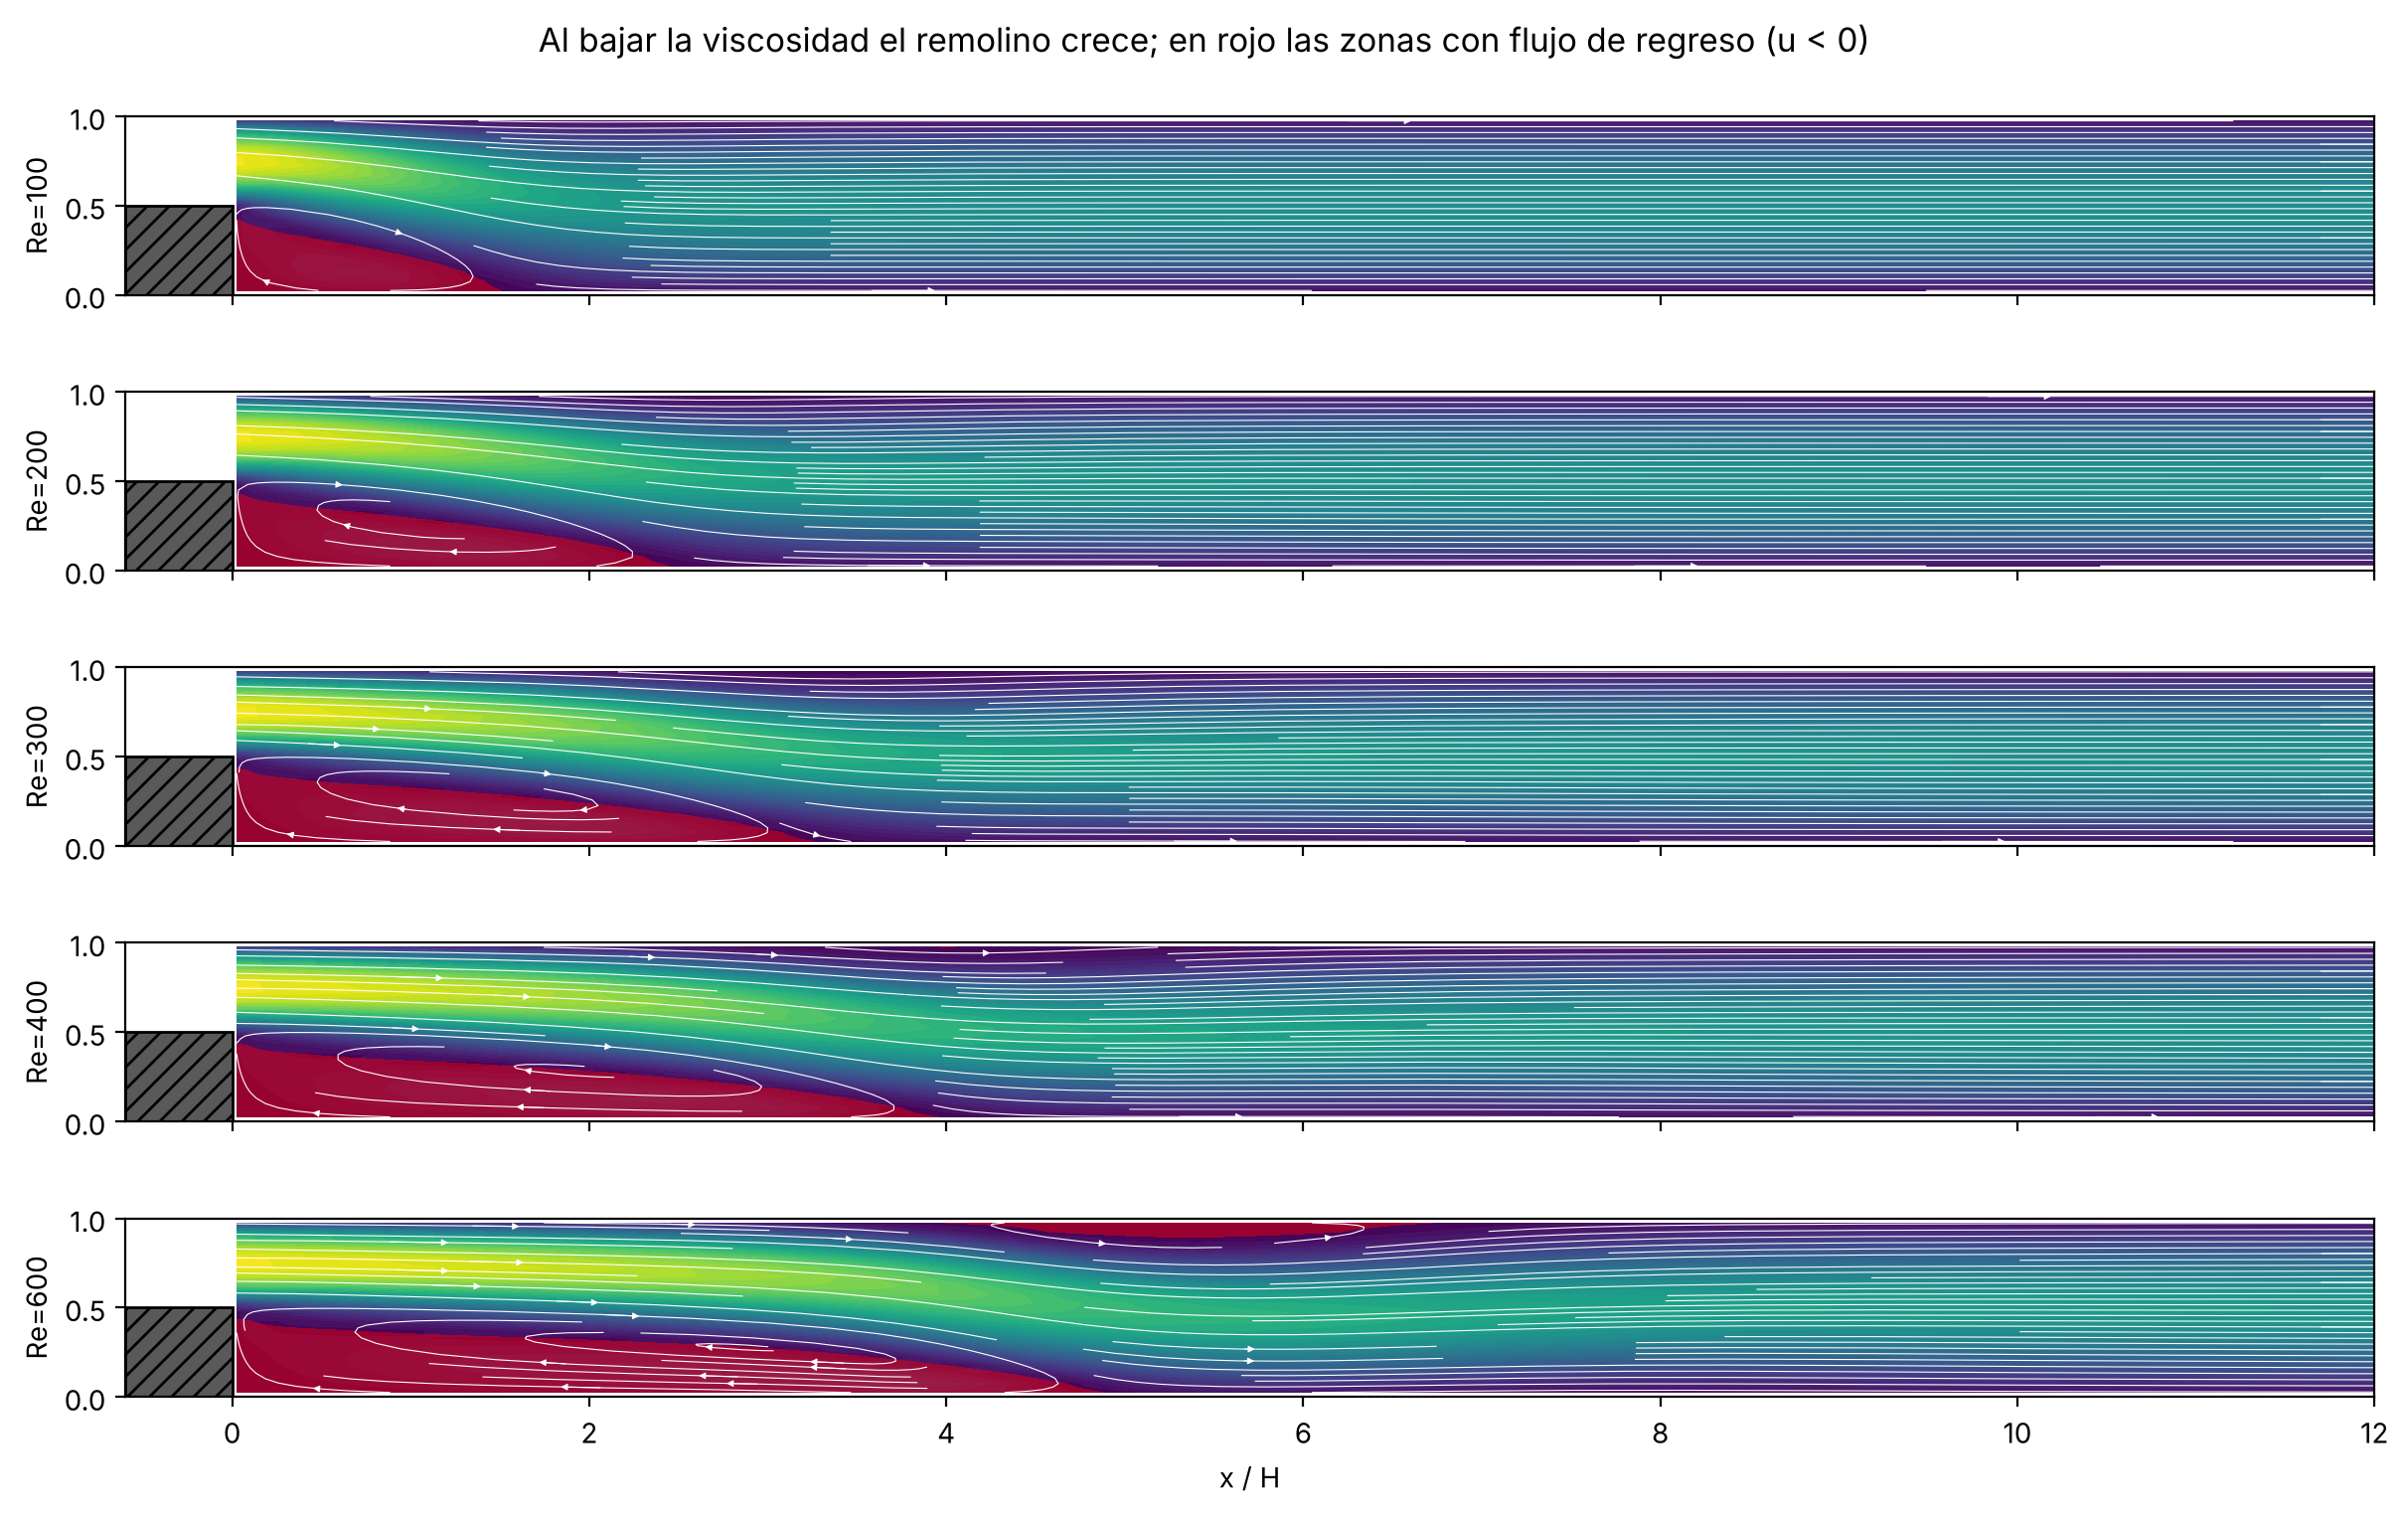

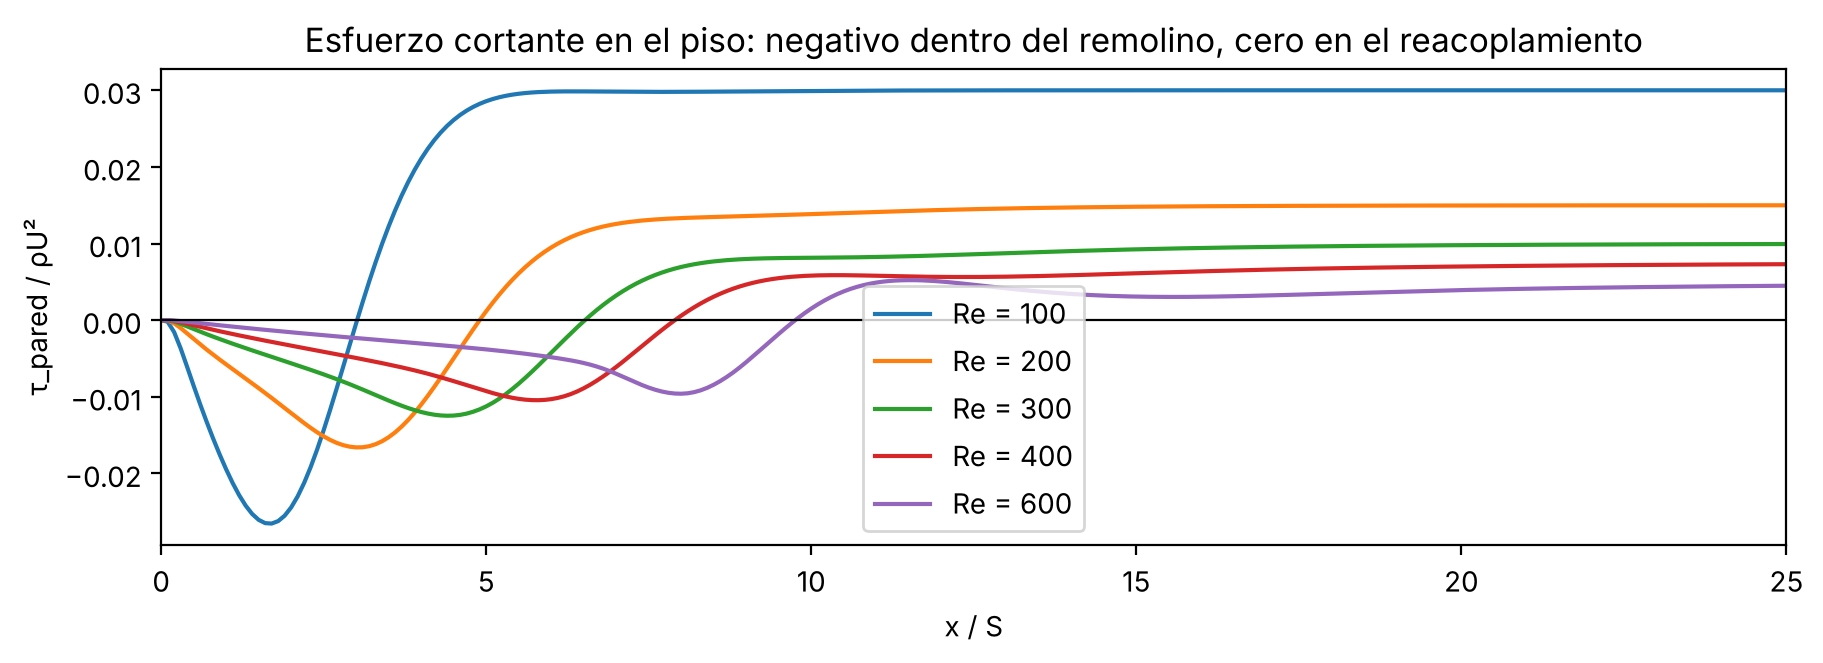

In [14]:
fig, ax = plt.subplots(len(casos_re), 1, figsize=(12, 7.5), sharex=True, constrained_layout=True)
for a, r in zip(ax, casos_re):
    m = r["m"]; uc, vc = velocidad_en_centros(r)
    a.contourf(m["x_p"], m["y_p"], np.hypot(uc, vc).T, levels=40, cmap="viridis")
    a.contourf(m["x_p"], m["y_p"], uc.T, levels=[-10, 0], colors="red", alpha=0.45)   # rojo: flujo de regreso (u < 0)
    a.streamplot(m["x_p"], m["y_p"], uc.T, vc.T, color="w", density=1.0, linewidth=0.4, arrowsize=0.5)
    dibujar_escalon(a); a.set_xlim(-0.6, 12); a.set_ylim(0, H); a.set_aspect("equal"); a.set_ylabel(f"Re={r['Re']}")
ax[-1].set_xlabel("x / H")
fig.suptitle("Al bajar la viscosidad el remolino crece; en rojo las zonas con flujo de regreso (u < 0)")
fig.savefig(FIG / "re_remolinos.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(9, 3.2), constrained_layout=True)
for r in casos_re:
    tau = r["nu"] * r["u"][:, 1] / (0.5 * r["m"]["dx"])        # esfuerzo cortante en el piso: nu * du/dy
    ax.plot(r["m"]["x_u"] / S, tau, label=f"Re = {r['Re']}")
ax.axhline(0, color="k", lw=0.8); ax.set_xlim(0, 25); ax.legend()
ax.set_xlabel("x / S"); ax.set_ylabel("τ_pared / ρU²")
ax.set_title("Esfuerzo cortante en el piso: negativo dentro del remolino, cero en el reacoplamiento")
fig.savefig(FIG / "re_cortante.png", dpi=150); plt.show()

Con menos viscosidad el chorro tarda más en "contagiar" su movimiento hacia el piso (la difusión viscosa es más lenta
frente a la convección), así que el remolino se alarga: **$x_r$ crece casi proporcional a $Re$**. Desde $Re \approx 400$
aparece un remolino en el techo, que empuja el chorro hacia abajo y frena el crecimiento del remolino de abajo.

### 5.2 Malla
Mismo caso (Re = 200) con 10, 20 y 40 celdas en la altura. Si al refinar el resultado casi no cambia, la malla es suficiente.

Re =  200 | NY =  10 | dt = 0.0333 | converge  en t =   45.1 (1354 pasos) | x_r/S = 4.47


Re =  200 | NY =  20 | dt = 0.0167 | converge  en t =   48.6 (2916 pasos) | x_r/S = 4.90


Re =  200 | NY =  40 | dt = 0.0083 | converge  en t =   51.0 (6123 pasos) | x_r/S = 5.11
NY =  10  (  1500 celdas)   x_r/S = 4.466
NY =  20  (  6000 celdas)   x_r/S = 4.899
NY =  40  ( 24000 celdas)   x_r/S = 5.114


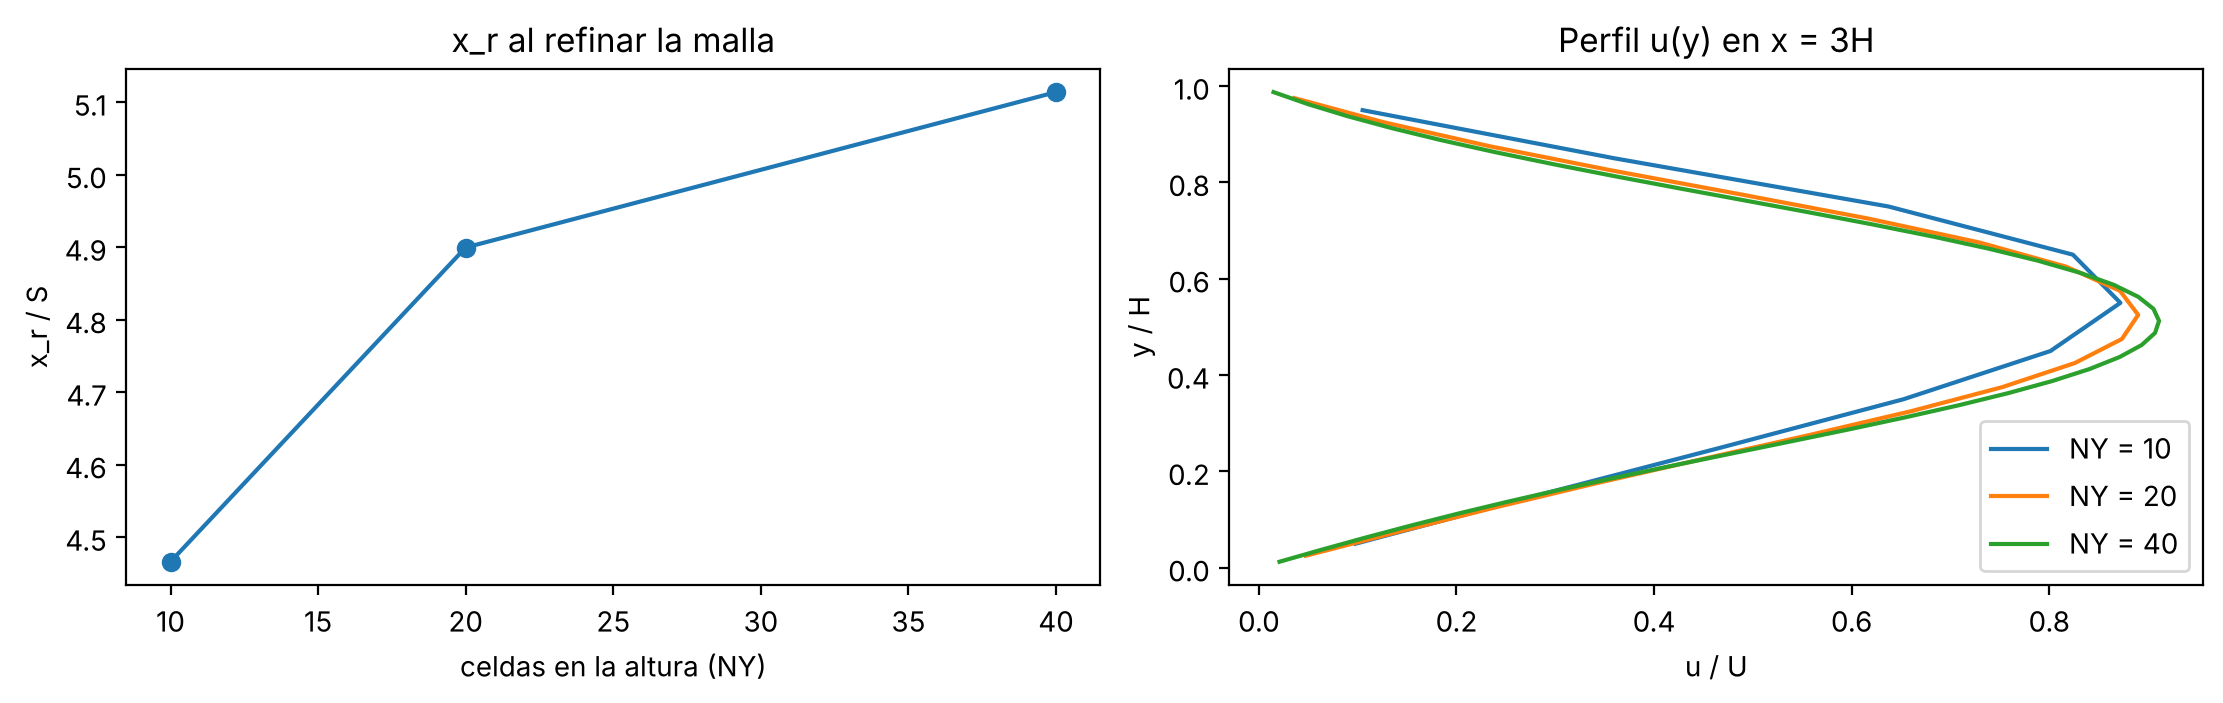

In [15]:
lista_ny = [10, 20, 40]
casos_malla = [simular(200, NY=ny, L=15.0) for ny in lista_ny]
for ny, r in zip(lista_ny, casos_malla):
    print(f"NY = {ny:3d}  ({r['m']['NX'] * ny:6d} celdas)   x_r/S = {r['xr']/S:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), constrained_layout=True)
ax[0].plot(lista_ny, [r["xr"] / S for r in casos_malla], "o-")
ax[0].set_xlabel("celdas en la altura (NY)"); ax[0].set_ylabel("x_r / S"); ax[0].set_title("x_r al refinar la malla")
for r, ny in zip(casos_malla, lista_ny):
    i = round(3.0 / r["m"]["dx"])
    ax[1].plot(r["u"][i, 1:-1], r["m"]["y_p"], label=f"NY = {ny}")
ax[1].set_xlabel("u / U"); ax[1].set_ylabel("y / H"); ax[1].set_title("Perfil u(y) en x = 3H"); ax[1].legend()
fig.savefig(FIG / "malla.png", dpi=150); plt.show()

El cambio de $x_r$ se reduce a la mitad cada vez que se duplica la malla (de 10 a 20: +0.43; de 20 a 40: +0.21),
así que el valor con malla infinitamente fina estaría cerca de 5.3. Con 20 celdas el error es de alrededor de 8 %, a
cambio de un cálculo 10 veces más rápido que con 40 (4 veces más celdas y la mitad de $\Delta t$).

### 5.3 Paso de tiempo
Re = 200, NY = 20. El límite CFL es $\Delta t = \Delta x/u_{max} = 0.05/1.5 = 0.033$.

Re =  200 | NY =  20 | dt = 0.0050 | converge  en t =   48.6 (9721 pasos) | x_r/S = 4.90


Re =  200 | NY =  20 | dt = 0.0167 | converge  en t =   48.6 (2910 pasos) | x_r/S = 4.90


Re =  200 | NY =  20 | dt = 0.0300 | converge  en t =   48.6 (1620 pasos) | x_r/S = 4.90
Re =  200 | NY =  20 | dt = 0.0450 | diverge   en t =    1.0 (22 pasos)


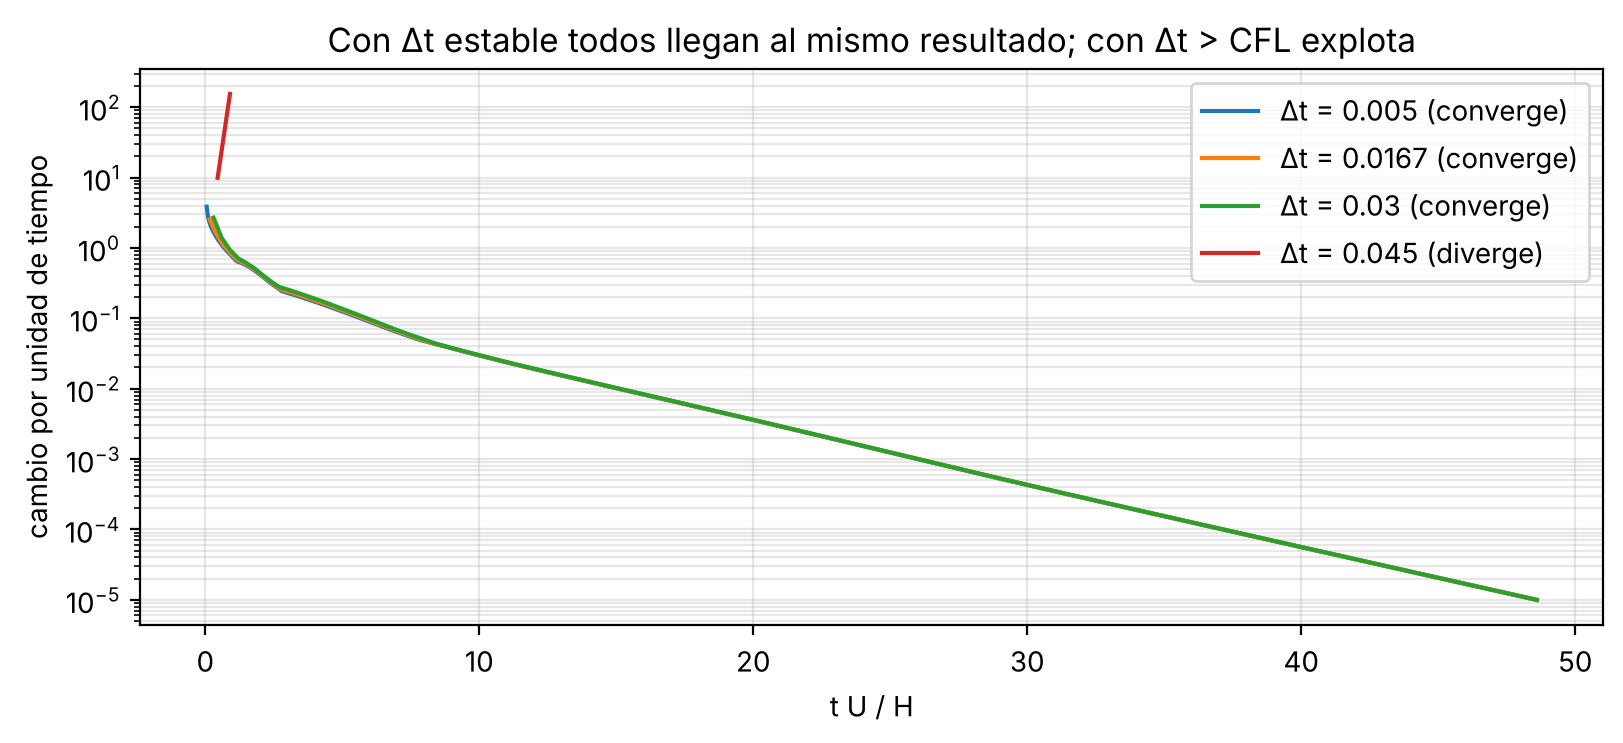

In [16]:
lista_dt = [0.005, 0.0167, 0.030, 0.045]
casos_dt = [simular(200, NY=20, L=15.0, dt=dt, t_max=150) for dt in lista_dt]

fig, ax = plt.subplots(figsize=(8, 3.6), constrained_layout=True)
for r in casos_dt:
    ax.semilogy(r["hist_t"], r["hist_cambio"], label=f"Δt = {r['dt']} ({r['estado']})")
ax.set_xlabel("t U / H"); ax.set_ylabel("cambio por unidad de tiempo"); ax.grid(alpha=0.3, which="both"); ax.legend()
ax.set_title("Con Δt estable todos llegan al mismo resultado; con Δt > CFL explota")
fig.savefig(FIG / "dt.png", dpi=150); plt.show()

Mientras $\Delta t$ cumple el CFL, el resultado final es **idéntico** ($x_r/S = 4.90$); un $\Delta t$ más grande sólo
llega en menos pasos. Con $\Delta t = 0.045$ (1.35 veces el límite) la solución explota en unas 20 iteraciones.

## 6. Comparación con la literatura
Valores de $x_r/S$ de simulaciones 2D publicadas para este mismo problema (tabla recopilada en arXiv:2507.16509;
la tendencia coincide con los experimentos de Armaly et al., 1983, hasta $Re \approx 400$).

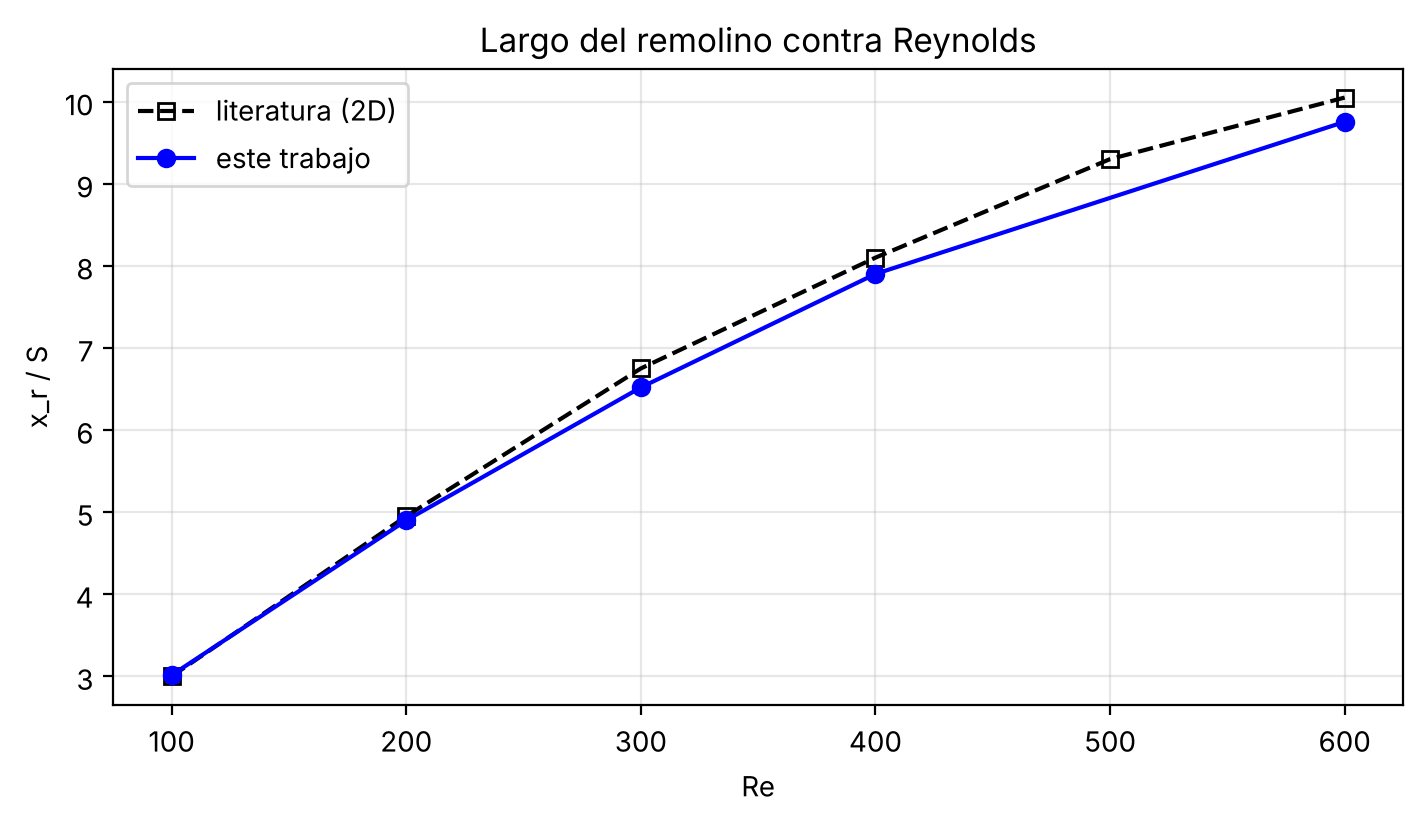

Re =  100   nuestro =  3.01   literatura =  3.00   diferencia = +0.5 %
Re =  200   nuestro =  4.90   literatura =  4.95   diferencia = -1.0 %
Re =  300   nuestro =  6.52   literatura =  6.75   diferencia = -3.4 %
Re =  400   nuestro =  7.90   literatura =  8.10   diferencia = -2.5 %
Re =  600   nuestro =  9.75   literatura = 10.05   diferencia = -2.9 %


In [17]:
re_lit = [100, 200, 300, 400, 500, 600]
xr_lit = [3.00, 4.95, 6.75, 8.10, 9.30, 10.05]

fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.plot(re_lit, xr_lit, "ks--", mfc="none", label="literatura (2D)")
ax.plot(lista_re, [r["xr"] / S for r in casos_re], "bo-", label="este trabajo")
ax.set_xlabel("Re"); ax.set_ylabel("x_r / S"); ax.grid(alpha=0.3); ax.legend()
ax.set_title("Largo del remolino contra Reynolds")
fig.savefig(FIG / "validacion.png", dpi=150); plt.show()

for r in casos_re:
    ref = np.interp(r["Re"], re_lit, xr_lit)
    print(f"Re = {r['Re']:4d}   nuestro = {r['xr']/S:5.2f}   literatura = {ref:5.2f}   diferencia = {100*(r['xr']/S - ref)/ref:+.1f} %")

Las diferencias son menores a 3.5 %. Parte del buen acuerdo es suerte: el estudio de malla dice que con malla muy fina
nuestro $x_r$ subiría ~8 %. Para un resultado más exacto habría que usar más celdas.

## Conclusiones
1. Resolvimos Navier–Stokes 2D con el método de proyección: velocidad de prueba → presión → corrección. La masa se conserva
   a precisión de máquina.
2. La simulación muestra la separación en la esquina, el remolino, el reacoplamiento y, para $Re \ge 400$, el remolino del techo.
3. **Viscosidad:** al bajarla (subir $Re$) el remolino crece, de $x_r/S = 3$ en Re = 100 a casi 10 en Re = 600.
4. **Malla:** el resultado converge al refinar; con 20 celdas el error es ~8 %.
5. **Paso de tiempo:** no cambia el resultado mientras se cumpla el CFL; si no, la solución explota.

**Referencias:** Armaly et al. (1983) *J. Fluid Mech.* 127; Gartling (1990) *Int. J. Numer. Methods Fluids* 11;
Chorin (1968) *Math. Comp.* 22; Griebel, Dornseifer y Neunhoeffer (1998) *Numerical Simulation in Fluid Dynamics*, SIAM;
arXiv:2507.16509 (2025); kangluosee, *CFD-Python* (GitHub).